# Tutorial 3f: Constrained Optimization with the Default Merit

### November 2026

An unconstrained optimizer is happy to produce a lens that cannot be made: an element
that thins to nothing, or an edge with negative thickness. This tutorial builds a
realistic design problem with three tools that keep things short and safe:

1. `problem.add_default_merit(...)`: a spot-size merit function in one call, using a
   few well-chosen pupil rays (Gaussian quadrature).
2. `problem.add_physical_constraints(...)`: thickness limits that the optimizer must
   obey (hard constraints).
3. `minimize(problem, "dls")`: the native damped least-squares optimizer, with an
   observer that records the run and a token that can cancel it.

The background is in the [Optimization Guide](../optimization_guide.rst) and
[Default Merit and Constraints](../optimization_merit_constraints.rst).

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import optiland.backend as be
from optiland.optimization import (
    CancelToken,
    DefaultMeritBlock,
    HistoryObserver,
    OptimizationProblem,
    minimize,
)
from optiland.optimization.operand.lens import LensOperand
from optiland.samples.objectives import CookeTriplet

## A starting design

We take the Optiland Cooke triplet and disturb its radii by about 15 % (with a fixed
seed) so that there is real work to do. The focal length of the original is 50 mm.

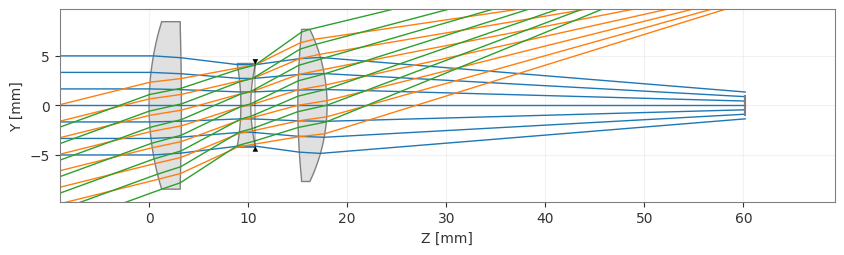

(<Figure size 1000x400 with 1 Axes>, <Axes: xlabel='Z [mm]', ylabel='Y [mm]'>)

In [2]:
def starting_lens():
    lens = CookeTriplet()
    rng = np.random.default_rng(3)
    for k in range(1, 7):
        geometry = lens.surfaces[k].geometry
        geometry.radius = geometry.radius * (1 + 0.15 * rng.standard_normal())
    return lens


lens = starting_lens()
lens.draw(num_rays=7)

## The default merit

`add_default_merit` adds **one block** of per-ray residuals instead of one operand per
number. With `rings=3, arms=6` it traces 18 rays for every field and wavelength; each
ray carries a quadrature weight, so `sum(r**2)` estimates the weighted RMS spot size
squared. `reference="centroid"` measures spots from their centroid (and from the
primary-wavelength centroid for other wavelengths, so lateral color counts).

We keep an ordinary operand for the focal length: blocks and operands mix freely. We
let all radii and the air and glass thicknesses vary, with a small lower bound on
thickness.

In [3]:
def make_problem(lens, constrained):
    problem = OptimizationProblem()

    problem.add_default_merit(lens, kind="spot", rings=3, arms=6)
    problem.add_operand("f2", target=50.0, weight=10.0, input_data={"optic": lens})

    num_surfaces = lens.surfaces.num_surfaces
    for k in range(1, num_surfaces - 1):
        problem.add_variable(lens, "radius", surface_number=k)
    for k in range(1, num_surfaces - 2):
        problem.add_variable(lens, "thickness", surface_number=k, min_val=0.1)

    if constrained:
        problem.add_physical_constraints(
            lens,
            min_center_glass=2.0,
            min_edge_glass=1.0,
            min_center_air=0.5,
            max_center=15.0,
        )
    return problem


free_lens = starting_lens()
free_problem = make_problem(free_lens, constrained=False)
free_problem.info()

╒════╤════════════════════════╤═══════════════════╕
│    │   Merit Function Value │   Improvement (%) │
╞════╪════════════════════════╪═══════════════════╡
│  0 │                11059.7 │                 0 │
╘════╧════════════════════════╧═══════════════════╛
╒════╤════════════════╤══════════╤══════════════╤══════════════╤══════════╤═══════════════╤═════════╤═════════╤════════════════╕
│    │ Operand Type   │   Target │ Min. Bound   │ Max. Bound   │   Weight │   Eff. Weight │   Value │   Delta │   Contrib. [%] │
╞════╪════════════════╪══════════╪══════════════╪══════════════╪══════════╪═══════════════╪═════════╪═════════╪════════════════╡
│  0 │ f2             │       50 │              │              │       10 │            10 │  60.513 │  10.513 │          99.93 │
╘════╧════════════════╧══════════╧══════════════╧══════════════╧══════════╧═══════════════╧═════════╧═════════╧════════════════╛
╒════╤═══════════════════╤════════╤═════════════╤══════════╤═══════════════╤════════╤══════════

The first table is the operand (`f2`), the second the default-merit block: one summary
row for 324 residuals (3 fields × 3 wavelengths × 18 rays × 2 coordinates).

## Run 1: no constraints

`minimize` with `method="dls"` is the native damped least-squares optimizer. A
`HistoryObserver` records the merit after every accepted step. Note that `minimize`
changes the lens in place.

In [4]:
free_history = HistoryObserver()
free_result = minimize(free_problem, "dls", observers=[free_history])

print(free_result.stop_reason)
print(f"merit {free_problem.sum_squared():.3e}   residual evaluations {free_result.n_evals}")

`ftol` termination condition is satisfied.
merit 7.761e-04   residual evaluations 229


Image quality is excellent, but look at the glass. The table lists the center and edge
thickness of every gap between surfaces (gap *k* lies after surface *k*):

In [5]:
def thickness(operand, lens, k):
    return float(np.ravel(be.to_numpy(operand(lens, k)))[0])


def thickness_table(lens):
    print(" gap   center    edge")
    for k in range(1, lens.surfaces.num_surfaces - 2):
        center = thickness(LensOperand.center_thickness, lens, k)
        edge = thickness(LensOperand.edge_thickness, lens, k)
        flag = "   <-- not buildable" if edge < 0 or center < 0.5 else ""
        print(f"  {k}   {center:7.3f} {edge:7.3f}{flag}")


thickness_table(free_lens)

 gap   center    edge
  1     4.376   2.347
  2     5.384   4.038
  3     0.100   0.830   <-- not buildable
  4     5.449   4.497
  5     0.100  -1.614   <-- not buildable


Some gaps have shrunk to the 0.1 mm bound and an edge thickness is negative: the
surfaces cross each other at the rim. The optimizer exploited the freedom we gave it.

## Run 2: physical constraints

`add_physical_constraints` places limits on every gap between lens surfaces in one
call. In the default `mode="constraint"` they are **hard** constraints: they are not
in the merit, and the optimizer must satisfy them. The gaps from the object and to the
image are never limited. Let us build the same problem, with limits, from the same
starting design.

In [6]:
lens = starting_lens()
problem = make_problem(lens, constrained=True)
problem.constraint_info()

╒════╤════════════════════════════╤════════════╤═══════════════╤════════════╤═════════════╤════════════╕
│    │ Constraint                 │ Kind       │   Eff. Weight │   Residual │   Violation │ Feasible   │
╞════╪════════════════════════════╪════════════╪═══════════════╪════════════╪═════════════╪════════════╡
│  0 │ #0 center_thickness >= 2   │ inequality │             1 │    -1.259  │      0      │ True       │
│  1 │ #1 center_thickness <= 15  │ inequality │             1 │   -11.74   │      0      │ True       │
│  2 │ #2 edge_thickness >= 1     │ inequality │             1 │    -0.6939 │      0      │ True       │
│  3 │ #3 center_thickness >= 0.5 │ inequality │             1 │    -5.508  │      0      │ True       │
│  4 │ #4 center_thickness <= 15  │ inequality │             1 │    -8.992  │      0      │ True       │
│  5 │ #5 center_thickness >= 2   │ inequality │             1 │     1      │      1      │ False      │
│  6 │ #6 center_thickness <= 15  │ inequality │       

Each limit is a row with its current residual and whether it is satisfied. The
starting design violates some of them; the optimizer first restores feasibility.

In [7]:
history = HistoryObserver()
result = minimize(problem, "dls", observers=[history])

print(result.stop_reason)
print(f"merit {problem.sum_squared():.3e}   residual evaluations {result.n_evals}")
print(f"success: {result.success}   max violation: {result.max_constraint_violation:.1e}")
thickness_table(lens)

`ftol` termination condition is satisfied.
merit 1.398e-03   residual evaluations 135
success: True   max violation: 3.3e-15
 gap   center    edge
  1     3.770   1.890
  2     5.991   4.671
  3     2.000   2.891
  4     4.273   3.474
  5     3.138   1.000


Every gap now respects its limit. The price is a higher merit than run 1 (about twice
as large here): the unconstrained result was only that good because it was not buildable. The result
also tells us **which constraints are binding**, and how much they cost:

In [8]:
problem.constraint_info()
for label in result.active_set:
    print(f"binding: {label:30s} multiplier {result.multipliers[label]:.2e}")

╒════╤════════════════════════════╤════════════╤═══════════════╤═════════════╤═════════════╤════════════╕
│    │ Constraint                 │ Kind       │   Eff. Weight │    Residual │   Violation │ Feasible   │
╞════╪════════════════════════════╪════════════╪═══════════════╪═════════════╪═════════════╪════════════╡
│  0 │ #0 center_thickness >= 2   │ inequality │             1 │  -1.77      │   0         │ True       │
│  1 │ #1 center_thickness <= 15  │ inequality │             1 │ -11.23      │   0         │ True       │
│  2 │ #2 edge_thickness >= 1     │ inequality │             1 │  -0.8904    │   0         │ True       │
│  3 │ #3 center_thickness >= 0.5 │ inequality │             1 │  -5.491     │   0         │ True       │
│  4 │ #4 center_thickness <= 15  │ inequality │             1 │  -9.009     │   0         │ True       │
│  5 │ #5 center_thickness >= 2   │ inequality │             1 │  -0         │   0         │ True       │
│  6 │ #6 center_thickness <= 15  │ inequality

A binding constraint with a large multiplier is a good candidate to relax: loosening it
would improve the merit the most.

Let us compare the two runs.

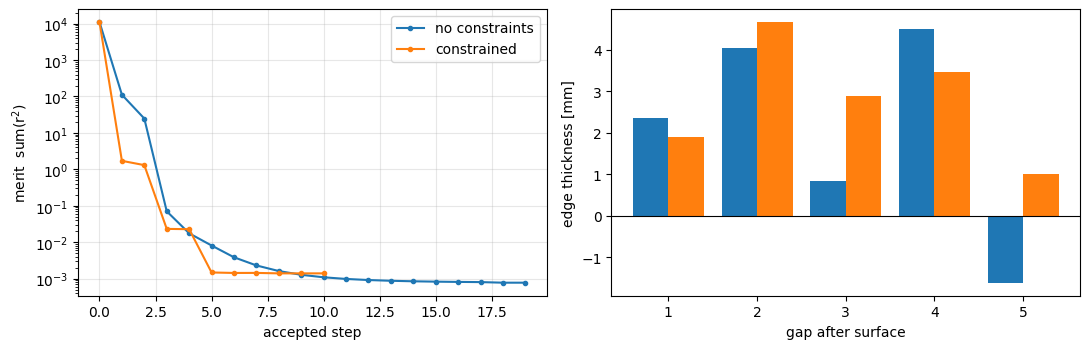

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for name, hist in (("no constraints", free_history), ("constrained", history)):
    axes[0].semilogy(
        [r["iteration"] for r in hist.records], [r["value"] for r in hist.records],
        marker="o", ms=3, label=name,
    )
axes[0].set_xlabel("accepted step")
axes[0].set_ylabel("merit  sum(r$^2$)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

for k in range(1, lens.surfaces.num_surfaces - 2):
    axes[1].bar(
        [k - 0.2, k + 0.2],
        [thickness(LensOperand.edge_thickness, free_lens, k),
         thickness(LensOperand.edge_thickness, lens, k)],
        width=0.4, color=["tab:blue", "tab:orange"],
    )
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set_xlabel("gap after surface")
axes[1].set_ylabel("edge thickness [mm]")
fig.tight_layout()
plt.show()

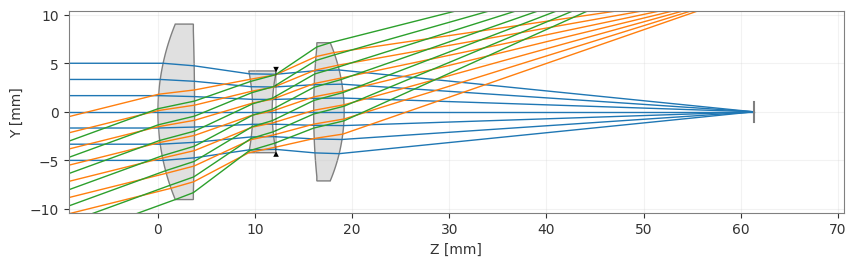

(<Figure size 1000x400 with 1 Axes>, <Axes: xlabel='Z [mm]', ylabel='Y [mm]'>)

In [10]:
lens.draw(num_rays=7)

## Watching and cancelling a run

An observer is any object with `on_start`, `on_step` and `on_end` methods, and a
`CancelToken` stops a run cleanly from anywhere (a button, a timer, another thread).
Here an observer cancels the run after three accepted steps. The lens keeps the best
design reached so far.

In [11]:
class StopAfter:
    def __init__(self, token, steps):
        self.token, self.steps = token, steps

    def on_start(self, state):
        print("start: merit", f"{state.value:.3e}")

    def on_step(self, state):
        print(f"step {state.iteration}: merit {state.value:.3e}  evaluations {state.n_evals}")
        if state.iteration >= self.steps:
            self.token.cancel()

    def on_end(self, state, result):
        print("end:", result.stop_reason)


cancel_lens = starting_lens()
cancel_problem = make_problem(cancel_lens, constrained=True)
token = CancelToken()
cancelled = minimize(
    cancel_problem, "dls", observers=[StopAfter(token, 3)], cancel_token=token
)

start: merit 1.106e+04
step 1: merit 1.715e+00  evaluations 13
step 2: merit 1.308e+00  evaluations 26


step 3: merit 2.326e-02  evaluations 38
end: Stopped by a stopping criterion: cancelled by user.


For quick progress output, `minimize(problem, "dls", disp=True)` attaches a
`ConsoleObserver`.

## How many rays does the merit need?

Gaussian quadrature uses few rays because it is an integral rule, not a sample. We can
check the choice on the final design by building the merit with more rings and arms:
if the value barely moves, three rings were enough.

In [12]:
for rings, arms in [(2, 6), (3, 6), (4, 8), (6, 12)]:
    check = OptimizationProblem()
    check.add_residual_block(DefaultMeritBlock(lens, "spot", rings=rings, arms=arms))
    print(f"rings={rings}, arms={arms:2d}:  sum(r^2) = {check.sum_squared():.4e}")

rings=2, arms= 6:  sum(r^2) = 1.3849e-03
rings=3, arms= 6:  sum(r^2) = 1.3983e-03
rings=4, arms= 8:  sum(r^2) = 1.3835e-03
rings=6, arms=12:  sum(r^2) = 1.3837e-03


## Summary and where to go next

| Task | Call |
|---|---|
| Spot or wavefront merit in one call | `problem.add_default_merit(lens, kind="spot" or "wavefront")` |
| Manufacturing limits on thickness | `problem.add_physical_constraints(lens, ...)` |
| Any other hard limit | `problem.add_constraint(operand, target=... or min_val=.../max_val=...)` |
| Run, watch and cancel | `minimize(problem, "dls", observers=[...], cancel_token=...)` |

Hard constraints are enforced by `"dls"` only; other optimizers raise an error rather
than ignore them. If you need another optimizer, use `mode="penalty"` instead (see
[Default Merit and Constraints](../optimization_merit_constraints.rst)). For method
selection, speed tips and failure behavior, see the [Optimization Guide](../optimization_guide.rst).